# Photoneo PhoXi 3D M — Capture Test

Connects to the live Photoneo PhoXi 3D M scanner, triggers a single frame, and displays the texture and depth map with matplotlib.

**Prerequisites:**
- `pip install phoxi-api` (already installed in cnos2)
- PhoXi Control running (`/usr/bin/PhoXiControl`)
- Scanner discovered in PhoXi Control's device list — if network discovery doesn't find it, use `Tools → Add Device via Address` with the scanner's IP

**Depth convention:** PhoXi DepthMap is in **millimetres** — `depth_scale = 1.0`.

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches

K:
[[731.1888    0.      325.4835 ]
 [  0.      656.7377  234.75359]
 [  0.        0.        1.     ]]
RGB:   (480, 640, 3)
Depth: (480, 640)  range 0–815 mm


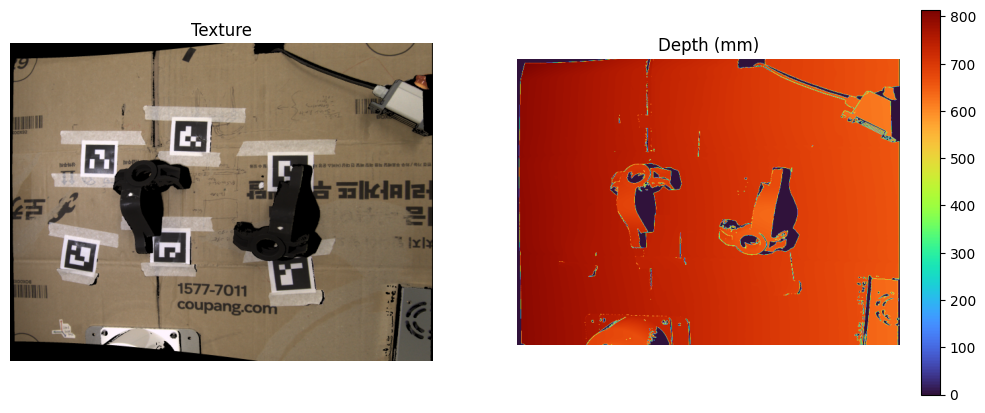

In [2]:
DEPTH_SCALE = 1.0  # PhoXi DepthMap is already in mm
GAMMA = 0.75  # ColorSettings/Gamma — only settable on scanners with a color camera unit

from phoxi_api import PhoXiControl, PhoXiDevice

phc = PhoXiControl()
device_id = next(
    d["id"] for d in phc.get_device_list(refresh=True)
    if d["type"] == "PhoXi3DScan" and not d["file_camera"]
)

with phc.connect(device_id) as device:
    device.set_trigger_mode(PhoXiDevice.TriggerMode.SOFTWARE)
    device.set_frame_settings({"DepthMap": True, "Texture": True})

    settings = device.settings()
    if settings.ColorSettings.Gamma.can_set():
        settings.ColorSettings.Gamma.value = GAMMA
    else:
        print("ColorSettings/Gamma not settable on this device (no color camera unit?)")

    device.start_acquisition()
    frame = device.get_frame(frame_id=device.trigger_frame(wait_grabbing_end=True), timeout_ms=60_000)

K = np.array(frame.Info["CameraMatrix"], dtype=np.float32).reshape(3, 3)
depth = np.array(frame.DepthMap, dtype=np.float32).squeeze()
texture = np.array(frame.Texture).squeeze()
rgb = np.stack([texture] * 3, axis=-1) if texture.ndim == 2 else texture
rgb = (rgb / rgb.max() * 255).clip(0, 255).astype(np.uint8)

# K was read at the scanner's native resolution; rescale it to match the
# 640x480 resize below, otherwise every downstream 3D unprojection
# (SAM-6D's point cloud, FoundationPose's render-based registration) is wrong.
orig_h, orig_w = depth.shape[:2]
rgb = cv2.resize(rgb, (640, 480), interpolation=cv2.INTER_AREA)
depth = cv2.resize(depth, (640, 480), interpolation=cv2.INTER_AREA)

sx, sy = 640 / orig_w, 480 / orig_h
K[0, 0] *= sx; K[0, 2] *= sx   # fx, cx
K[1, 1] *= sy; K[1, 2] *= sy   # fy, cy

print(f"K:\n{K}")
print(f"RGB:   {rgb.shape}")
print(f"Depth: {depth.shape}  range {depth.min():.0f}–{depth.max():.0f} mm")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(rgb); axes[0].set_title("Texture"); axes[0].axis("off")
im = axes[1].imshow(depth, cmap="turbo"); axes[1].set_title("Depth (mm)"); axes[1].axis("off")
fig.colorbar(im, ax=axes[1], fraction=0.046)
plt.show()


In [3]:
import pickle

data = [K, rgb, depth, texture]

with open("data_sample_neo_17.pkl", "wb") as file:
    pickle.dump(data, file)

In [4]:
import torch

from src.sam6d import SAM6D

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {DEVICE}")

CAD_PATHS = [
    "/home/joon/Downloads/cad_files/steering_knuckle/steering-knuckle-thunder-truck-r1-r.stl",
]
MODEL_IDS = ["steering_knuckle"]
TEMPLATE_DIRS = ["./sam6d_templates_steering_knuckle"]
MESH_COLORS = [(int(0.01*255), int(0.01*255), int(0.01*255))]   # steering_knuckle — dark warm gray  (~22% luminance)
FLAT_SHADING = True
PHYSICAL_SCALE = 3.0  # real object is ~3x larger than this CAD model -> FoundationPoseRefiner's physical_scale
CAD_PATHS_BY_ID = dict(zip(MODEL_IDS, CAD_PATHS))


/home/joon/.virtualenvs/cnos2/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


Using device: cuda


In [5]:
model = SAM6D(
    cad_path=CAD_PATHS,
    model_ids=MODEL_IDS,
    template_dirs=TEMPLATE_DIRS,
    device=DEVICE,

    physical_scale=PHYSICAL_SCALE,  # must match FoundationPoseRefiner's physical_scale below

    sam_model_type="vit_h",
    stability_score_thresh=0.97,

    reset_templates=False,
    mesh_color=MESH_COLORS,
    flat_shading=FLAT_SHADING,
    roughness=0.9,
    metallic=0.0,
    light_energy=1100,

    det_score_thresh=0.375,
    confidence_thresh=0.3,
    visible_thred=0.5,
    n_template_view=42,
    min_component_area_ratio=0.005,
    mask_overlap_thresh=0.2,
    pose_score_thresh=0.375,

    half_precision=False,
)


load pre-trained checkpoint from: /home/joon/Projects/cnos/checkpoints/mae_pretrain_vit_base.pth


In [6]:
results = model(rgb, depth, K, depth_scale=DEPTH_SCALE)

N = len(results["poses"])
print(f"Detections: {N}")
for i in range(N):
    print(
        f"[{i}]  model_id={results['model_ids'][i]!r:22s}"
        f"  ism={results['ism_scores'][i]:.3f}"
        f"  pose_score={results['pose_scores'][i]:.3f}"
    )


Detections: 2
[0]  model_id='steering_knuckle'      ism=0.577  pose_score=0.508
[1]  model_id='steering_knuckle'      ism=0.601  pose_score=0.552


In [7]:
from scipy.spatial.transform import Rotation

for i, pose in enumerate(results["poses"]):
    x, y, z = pose["t"]
    roll, pitch, yaw = Rotation.from_matrix(pose["R"]).as_euler("xyz", degrees=True)
    print(
        f"[{i}] {results['model_ids'][i]:16s}"
        f"  XYZ(mm)=({x:8.1f}, {y:8.1f}, {z:8.1f})"
        f"  RPY(deg)=({roll:7.1f}, {pitch:7.1f}, {yaw:7.1f})"
        f"  score={pose['score']:.3f}"
    )


[0] steering_knuckle  XYZ(mm)=(   336.2,    959.0,   -557.9)  RPY(deg)=(   47.7,    -4.9,   175.5)  score=0.508
[1] steering_knuckle  XYZ(mm)=(   122.7,   -445.6,   2145.2)  RPY(deg)=( -109.9,    22.6,  -158.6)  score=0.552


In [8]:
import json
from scipy.spatial.transform import Rotation

# Debug-only preview of the raw SAM-6D estimate (camera frame, before FoundationPose
# refinement and before the T_cam_base transform). NOT sent anywhere — the actual
# send-to-robot step happens after refinement, in the pose_base cell below.
detections = []
for i, pose in enumerate(results["poses"]):
    x, y, z = pose["t"]
    roll, pitch, yaw = Rotation.from_matrix(pose["R"]).as_euler("xyz", degrees=True)
    detections.append({
        "model_id": results["model_ids"][i],
        "xyz_mm": [float(x), float(y), float(z)],
        "rpy_deg": [float(roll), float(pitch), float(yaw)],
        "score": float(pose["score"]),
    })

print(json.dumps(detections, indent=2))


[
  {
    "model_id": "steering_knuckle",
    "xyz_mm": [
      336.1883850097656,
      958.98095703125,
      -557.9249267578125
    ],
    "rpy_deg": [
      47.71873118821009,
      -4.946438411807021,
      175.54221657023618
    ],
    "score": 0.5082067847251892
  },
  {
    "model_id": "steering_knuckle",
    "xyz_mm": [
      122.67752838134766,
      -445.6346435546875,
      2145.23291015625
    ],
    "rpy_deg": [
      -109.85849591514398,
      22.55881147074899,
      -158.59155273489858
    ],
    "score": 0.5515255331993103
  }
]


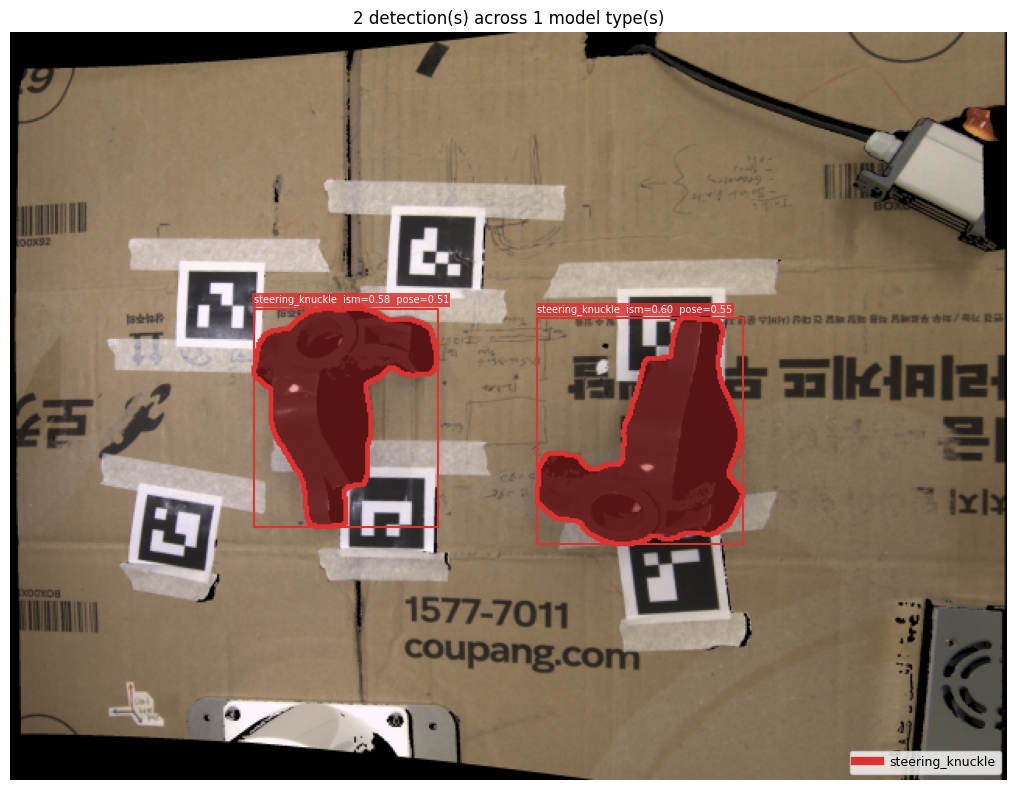

In [9]:
def visualize_multi_model_detections(rgb, results, alpha=0.4):
    import cv2

    MODEL_PALETTE = {
        "helical_gear":    np.array([102, 102, 102]),
        "carrier_flipper": np.array([ 50, 120, 240]),
        "carrier_gear":    np.array([  0,  89, 242]),
    }
    FALLBACK_COLORS = [
        np.array([220,  50,  50]),
        np.array([ 50, 200,  80]),
        np.array([180,  50, 220]),
        np.array([ 50, 220, 220]),
    ]

    masks       = results["masks"]
    boxes       = results["boxes"]
    ism_scores  = results["ism_scores"]
    pose_scores = results["pose_scores"]
    model_ids   = results.get("model_ids", ["unknown"] * len(masks))

    if len(masks) == 0:
        fig, ax = plt.subplots(figsize=(10, 6))
        ax.imshow(rgb)
        ax.set_title("No detections")
        ax.axis("off")
        plt.show()
        return

    unique_models = sorted(set(model_ids))
    color_map = {}
    fallback_idx = 0
    for mid in unique_models:
        if mid in MODEL_PALETTE:
            color_map[mid] = MODEL_PALETTE[mid]
        else:
            color_map[mid] = FALLBACK_COLORS[fallback_idx % len(FALLBACK_COLORS)]
            fallback_idx += 1

    order   = np.argsort([-m.sum() for m in masks])
    overlay = rgb.copy().astype(float)
    for i in order:
        color = color_map[model_ids[i]]
        overlay[masks[i].astype(bool)] = (
            (1 - alpha) * overlay[masks[i].astype(bool)] + alpha * color
        )

    canvas = overlay.astype(np.uint8)
    for i in order:
        color = color_map[model_ids[i]]
        contours, _ = cv2.findContours(
            masks[i].astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
        )
        cv2.drawContours(canvas, contours, -1, color.tolist(), 2)

    fig, ax = plt.subplots(figsize=(12, 8))
    ax.imshow(canvas)

    for i, (box, ism_s, pose_s, mid) in enumerate(
        zip(boxes, ism_scores, pose_scores, model_ids)
    ):
        x1, y1, x2, y2 = box
        color = color_map[mid] / 255.0
        rect = patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            linewidth=1.5, edgecolor=color, facecolor="none"
        )
        ax.add_patch(rect)
        ax.text(
            x1, y1 - 4,
            f"{mid}  ism={ism_s:.2f}  pose={pose_s:.2f}",
            color="white", fontsize=7,
            bbox=dict(facecolor=color, alpha=0.85, pad=1, edgecolor="none"),
        )

    for mid, color in color_map.items():
        ax.plot([], [], color=color / 255.0, linewidth=6, label=mid)
    ax.legend(loc="lower right", fontsize=9, framealpha=0.8)

    ax.axis("off")
    ax.set_title(f"{len(masks)} detection(s) across {len(unique_models)} model type(s)")
    plt.tight_layout()
    plt.show()


visualize_multi_model_detections(rgb, results)


In [10]:
from src.foundationpose import FoundationPoseRefiner

fp = FoundationPoseRefiner(
    cad_path=CAD_PATHS,
    device=DEVICE,

    # Mesh units → metres conversion (1/1000 = mm→m, which is the default for STL/CAD files)
    mesh_scale=1/1000.0,   # STL units → metres (1/1000 for mm STL)
    physical_scale=PHYSICAL_SCALE,  # compensate for CAD model being smaller than the real object

    # Refinement iterations: more = slower but more accurate
    est_refine_iter=5,    # for register() — first frame
    track_refine_iter=2,  # for track()    — subsequent frames

    # Detection filtering
    max_detections=4,   # None = refine all SAM-6D detections; int N = top-N by pose_score
    min_pose_score=0.0,    # skip SAM-6D detections with pose_score below this threshold

    debug=0,               # 0 = silent; ≥2 = saves debug renders to debug_dir

    # Memory management — uncomment to reduce VRAM usage
    # half_precision=True,  # fp16 weights for RefineNet + ScoreNet (~50% less VRAM)
    # lazy_load=True,       # defer loading RefineNet/ScoreNet until first refine_from_sam6d() call
)

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


[__init__()] welcome
[__init__()] self.cfg: 
 lr: 0.0001
c_in: 6
zfar: .inf
debug: null
w_rot: 0.1
n_view: 1
run_id: null
use_BN: true
rot_rep: axis_angle
ckpt_dir: /home/joon/Projects/cnos/FoundationPose-main/learning/training/../../weights/2023-10-28-18-33-37/model_best.pth
exp_name: 2023-10-28-18-33-37
save_dir: /tmp/2023-10-28-18-33-37/
loss_type: l2
optimizer: adam
trans_rep: tracknet
batch_size: 64
crop_ratio: 1.2
use_normal: false
BN_momentum: 0.1
max_num_key: null
warmup_step: -1
input_resize:
- 160
- 160
max_step_val: 1000
normal_uint8: false
vis_interval: 1000
weight_decay: 0
n_max_objects: null
normalize_xyz: true
clip_grad_norm: 'Infinity'
rot_normalizer: 0.3490658503988659
trans_normalizer:
- 0.019999999552965164
- 0.019999999552965164
- 0.05000000074505806
max_step_per_epoch: 25000
val_epoch_interval: 10
n_dataloader_workers: 60
enable_amp: true
use_mask: false

[__init__()] self.h5_file:
[__init__()] Using pretrained model from /home/joon/Projects/cnos/FoundationPose-mai

Warp 1.13.0 initialized:
   CUDA Toolkit 12.9, Driver 13.2
   Devices:
     "cpu"      : "x86_64"
     "cuda:0"   : "NVIDIA RTX A6000" (47 GiB, sm_86, mempool enabled)
   Kernel cache:
     /home/joon/.cache/warp/1.13.0


[__init__()] init done
[_load_models()] FoundationPose models loaded.


In [11]:
# Pass SAM-6D results directly — FoundationPose registers on each detection's mask.
# `results` is the dict returned by the SAM6D forward pass above.
refined = fp(rgb, depth, K, results, depth_scale=DEPTH_SCALE)

print(f"Refined {len(refined)} detection(s)\n")
for i, r in enumerate(refined):
    print(
        f"[{i}]  detection_idx={r['detection_idx']}"
        f"  sam6d_score={r['sam6d_score']:.3f}"
        f"  fp_score={r['fp_score']:.4f}"
    )
    print(f"     pose (4×4, translation in metres):")
    print(f"     {r['pose']}")

[_load_models()] FoundationPose models loaded.
[reset_object()] self.diameter:0.1593375096248604, vox_size:0.00796687548124302
[reset_object()] self.pts:torch.Size([300, 3])
[reset_object()] reset done
[make_rotation_grid()] cam_in_obs:(42, 4, 4)
[make_rotation_grid()] rot_grid:(252, 4, 4)


num original candidates = 252


[make_rotation_grid()] after cluster, rot_grid:(252, 4, 4)
[make_rotation_grid()] self.rot_grid: torch.Size([252, 4, 4])
[register()] Welcome
[register()] poses:(252, 4, 4)
[register()] after viewpoint, add_errs min:-1.0
/home/joon/.virtualenvs/cnos2/lib/python3.12/site-packages/torch/__init__.py:1323: UserWarning: torch.set_default_tensor_type() is deprecated as of PyTorch 2.1, please use torch.set_default_dtype() and torch.set_default_device() as alternatives. (Triggered internally at /pytorch/torch/csrc/tensor/python_tensor.cpp:434.)
  _C._set_default_tensor_type(t)
[predict()] ob_in_cams:(252, 4, 4)
[predict()] self.cfg.use_normal:False
[predict()] trans_normalizer:[0.019999999552965164, 0.019999999552965164, 0.05000000074505806], rot_normalizer:0.3490658503988659
[predict()] making cropped data
[make_crop_data_batch()] Welcome make_crop_data_batch
[make_crop_data_batch()] make tf_to_crops done
[make_crop_data_batch()] render done
[make_crop_data_batch()] warp done
[make_crop_data_

num of pose after clustering: 252
Module Utils 9293bed load on device 'cuda:0' took 0.52 ms  (cached)


/home/joon/Projects/cnos/FoundationPose-main/learning/training/predict_pose_refine.py:190: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=self.amp):
[predict()] forward done
[predict()] making cropped data
[make_crop_data_batch()] Welcome make_crop_data_batch
[make_crop_data_batch()] make tf_to_crops done
[make_crop_data_batch()] render done
[make_crop_data_batch()] warp done
[make_crop_data_batch()] pose batch data done
[predict()] forward start
[predict()] forward done
[predict()] making cropped data
[make_crop_data_batch()] Welcome make_crop_data_batch
[make_crop_data_batch()] make tf_to_crops done
[make_crop_data_batch()] render done
[make_crop_data_batch()] warp done
[make_crop_data_batch()] pose batch data done
[predict()] forward start
[predict()] forward done
[predict()] making cropped data
[make_crop_data_batch()] Welcome make_crop_data_batch
[make_crop_data_batch

num original candidates = 252
num of pose after clustering: 252


[make_rotation_grid()] after cluster, rot_grid:(252, 4, 4)
[make_rotation_grid()] self.rot_grid: torch.Size([252, 4, 4])
[register()] Welcome
[register()] poses:(252, 4, 4)
[register()] after viewpoint, add_errs min:-1.0
[predict()] ob_in_cams:(252, 4, 4)
[predict()] self.cfg.use_normal:False
[predict()] trans_normalizer:[0.019999999552965164, 0.019999999552965164, 0.05000000074505806], rot_normalizer:0.3490658503988659
[predict()] making cropped data
[make_crop_data_batch()] Welcome make_crop_data_batch
[make_crop_data_batch()] make tf_to_crops done
[make_crop_data_batch()] render done
[make_crop_data_batch()] warp done
[make_crop_data_batch()] pose batch data done
[predict()] forward start
[predict()] forward done
[predict()] making cropped data
[make_crop_data_batch()] Welcome make_crop_data_batch
[make_crop_data_batch()] make tf_to_crops done
[make_crop_data_batch()] render done
[make_crop_data_batch()] warp done
[make_crop_data_batch()] pose batch data done
[predict()] forward sta

Refined 2 detection(s)

[0]  detection_idx=1  sam6d_score=0.552  fp_score=53.0312
     pose (4×4, translation in metres):
     [[ 0.27354673  0.02532499  0.96152514  0.06861962]
 [-0.44168228 -0.8847194   0.14895737  0.0335801 ]
 [ 0.8544524  -0.46543548 -0.23082653  0.6604871 ]
 [ 0.          0.          0.          1.        ]]
[1]  detection_idx=0  sam6d_score=0.508  fp_score=58.2188
     pose (4×4, translation in metres):
     [[ 0.25558582 -0.03098472 -0.9662899  -0.11945442]
 [ 0.4320851   0.8977707   0.08549986  0.00214299]
 [ 0.8648575  -0.439372    0.24284554  0.70107573]
 [ 0.          0.          0.          1.        ]]


In [12]:
print(refined)

[{'pose': array([[ 0.27354673,  0.02532499,  0.96152514,  0.06861962],
       [-0.44168228, -0.8847194 ,  0.14895737,  0.0335801 ],
       [ 0.8544524 , -0.46543548, -0.23082653,  0.6604871 ],
       [ 0.        ,  0.        ,  0.        ,  1.        ]],
      dtype=float32), 'fp_score': 53.03125, 'sam6d_score': 0.5515255331993103, 'mask': array([[False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       ...,
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False]], shape=(480, 640)), 'box': array([338, 183, 470, 328]), 'detection_idx': 1, 'model_idx': 0, 'model_id': 'steering_knuckle'}, {'pose': array([[ 0.25558582, -0.03098472, -0.9662899 , -0.11945442],
       [ 0.4320851 ,  0.8977707 ,  0.08549986,  0.00214299],
       [ 0.8648575 , -0.439372  ,  0.24284554,  0.7010

## FoundationPose sanity check — project pose + point cloud onto image

Reprojects each detection's `refined[i]["pose"]` (camera frame) and its CAD point
cloud (`fp._meshes[model_idx].vertices` — same scaled/centred array FoundationPose
registered against) directly onto the capture, so a misregistration shows up as a
visible mismatch between the red points and the actual object.

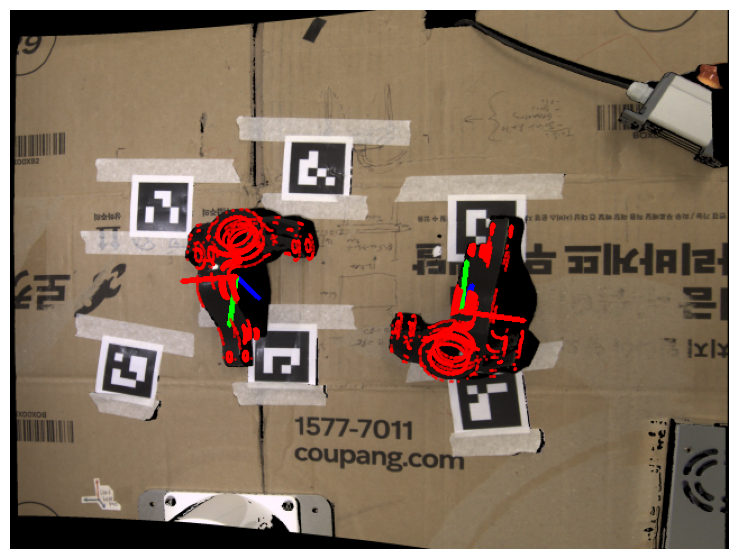

In [13]:
def project_fp_pose(rgb, refined, meshes, K, stride=2, axis_len_m=0.05):
    canvas = rgb.copy()
    pts2d = []
    for r in refined:
        rvec, _ = cv2.Rodrigues(r["pose"][:3, :3].astype(np.float64))
        tvec = r["pose"][:3, 3].astype(np.float64)
        verts = meshes[r["model_idx"]].vertices[::stride].astype(np.float64)
        px, _ = cv2.projectPoints(verts, rvec, tvec, K.astype(np.float64), np.zeros(5))
        pts2d.append(px[:, 0])
        cv2.drawFrameAxes(canvas, K.astype(np.float64), np.zeros(5), rvec, tvec, axis_len_m)
    return canvas, pts2d

canvas, pts2d = project_fp_pose(rgb, refined, fp._meshes, K)
plt.figure(figsize=(10, 7)); plt.imshow(canvas)
for px in pts2d:
    plt.scatter(px[:, 0], px[:, 1], s=2, c="red", alpha=0.5)
plt.axis("off"); plt.show()

In [14]:
import json
import subprocess
from datetime import datetime
from scipy.spatial.transform import Rotation

T_cam_base = [[-0.03823340, -0.99926283, -0.00346369, 0.28595885],
[-0.97867277, 0.03674502, 0.20211236, -0.28943317],
[-0.20183609, 0.01111726, -0.97935622, 0.70415632],
[0.00000000, 0.00000000, 0.00000000, 1.00000000]]


T_cam_base = np.array(T_cam_base)

# Camera frame -> robot-base frame. Both T_cam_base and refined[i]["pose"] have
# translation in metres, so this is a plain 4x4 compose (no mm/m conversion).
for r in refined:
    r["pose_base"] = T_cam_base @ r["pose"]

for i, r in enumerate(refined):
    x, y, z = r["pose_base"][:3, 3]
    print(f"[{i}] {r['model_id']:16s}  XYZ_base(m)=({x:+.4f}, {y:+.4f}, {z:+.4f})")
    print(f"     pose_base (4×4):")
    print(f"     {r['pose_base']}")

# Send the FoundationPose-refined, base-frame poses — this is the value the robot
# should actually act on (not the raw camera-frame SAM-6D estimate from the earlier
# debug cell) — along with the rgb/depth frame they were computed from, so the
# receiving side can re-check/re-render against the exact same capture.
detections_base = []
for r in refined:
    x, y, z = r["pose_base"][:3, 3]
    roll, pitch, yaw = Rotation.from_matrix(r["pose_base"][:3, :3]).as_euler("xyz", degrees=True)
    detections_base.append({
        "model_id": r["model_id"],
        "xyz_mm": [float(x * 1000.0), float(y * 1000.0), float(z * 1000.0)],
        "rpy_deg": [float(roll), float(pitch), float(yaw)],
        "fp_score": float(r["fp_score"]),
        "sam6d_score": float(r["sam6d_score"]),
    })

ts = datetime.now().strftime("%Y%m%d_%H%M%S")
json_path  = f"/tmp/obj_pose_base_{ts}.json"
rgb_path   = f"/tmp/obj_rgb_{ts}.png"
depth_path = f"/tmp/obj_depth_{ts}.npy"

with open(json_path, "w") as f:
    json.dump(detections_base, f, indent=2)
cv2.imwrite(rgb_path, cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR))
np.save(depth_path, depth)  # float32 mm, same array FoundationPose/SAM-6D used

subprocess.run(["scp", json_path, rgb_path, depth_path, "v@172.30.1.60:~/received/"], check=True)
print(
    f"Sent {len(detections_base)} detection(s) + rgb + depth -> v@172.30.1.60:~/received/ "
    f"(obj_pose_base_{ts}.json, obj_rgb_{ts}.png, obj_depth_{ts}.npy)"
)


[0] steering_knuckle  XYZ_base(m)=(+0.2475, -0.2219, +0.0438)
     pose_base (4×4):
     [[ 0.4279385   0.88471105 -0.18481043  0.24749222]
 [-0.11124697 -0.15136417 -0.98219793 -0.22186282]
 [-0.89693514  0.44087997  0.03364692  0.04382756]
 [ 0.          0.          0.          1.        ]]
[1] steering_knuckle  XYZ_base(m)=(+0.2860, -0.0308, +0.0417)
     pose_base (4×4):
     [[-0.44453409 -0.89440239 -0.04933343  0.28595628]
 [-0.05945952 -0.02549001  0.99790537 -0.03075157]
 [-0.89378641  0.44653629 -0.04184959  0.04168748]
 [ 0.          0.          0.          1.        ]]
Sent 2 detection(s) + rgb + depth -> v@172.30.1.60:~/received/ (obj_pose_base_20260714_162740.json, obj_rgb_20260714_162740.png, obj_depth_20260714_162740.npy)


## Manual 6DoF grasp definition

Hand-author grasp poses per object (position + full orientation).

In [15]:
from scipy.spatial.transform import Rotation

# Grasps are defined in the SAME frame as refined[i]["pose"]: origin at the CAD
# mesh's centroid, axes matching the STL's native orientation, units in metres
# (see src/foundationpose.py — vertices are scaled then re-centered on centroid
# before pose estimation). Edit the fields by hand and re-run the viz cell below.
#
# Orientation is given directly as a spatial approach line + a roll, NOT as
# Euler angles — an Euler triple doesn't let you say "point the approach axis
# this way" without reverse-engineering it, so approach direction here is a
# free vector in 3D relative to the object, not restricted to any object axis:
#   approach_azimuth_deg / approach_elevation_deg — spherical angles (relative
#       to the object frame) giving the approach axis (local +Z) as a unit
#       vector. elevation=+90 -> straight along +Z; elevation=0 -> in the XY
#       plane at the given azimuth. The gripper backs off along +Z from the
#       grasp position to reach the hover position, and moves along -Z from
#       hover to grip.
#   jaw_roll_deg — rotation of the jaw-opening axis (local +X) about the
#       approach axis. Together with the approach angles this fully determines
#       orientation (3 DOF total, same as an Euler triple, just parameterized
#       around the axis that actually matters for approach planning).
#   jaw_width_m / jaw_length_m — fingers sit at x = ±jaw_width_m/2, extending
#       from the grasp plane (z=0, the fingertip/contact line) back along +Z
#       for jaw_length_m (drawing only, not a physical constraint).
GRASPS = {
    "steering_knuckle": [
        {
            "t_m": [-0.01, 0.005, 0.0125],
            "approach_azimuth_deg": -45,
            "approach_elevation_deg": 0,
            "jaw_roll_deg": 90,
            "jaw_width_m": 0.025,   # distance between jaw faces at the grasp position
            "jaw_length_m": 0.01,  # finger length, for drawing only
            "hover_dist_m": -0.06,  # grasp -> hover distance, along +Z (approach axis)
        },
    ],
}

def approach_vector(g):
    """Unit approach-axis direction (local +Z), from spherical angles relative to the object frame."""
    az = np.radians(g["approach_azimuth_deg"])
    el = np.radians(g["approach_elevation_deg"])
    return np.array([np.cos(el) * np.cos(az), np.cos(el) * np.sin(az), np.sin(el)])

def grasp_R(g):
    """Rotation matrix from an approach direction + roll about it (see comment above).
    local +Z = approach axis, local +X = jaw-opening axis."""
    z = approach_vector(g)
    # reference "up" for building the perpendicular basis; swap to avoid degeneracy
    # when the approach axis is itself near-parallel to the primary reference
    up = np.array([0.0, 1.0, 0.0]) if abs(z[2]) > 0.99 else np.array([0.0, 0.0, 1.0])
    x0 = np.cross(up, z); x0 /= np.linalg.norm(x0)
    y0 = np.cross(z, x0)
    roll = np.radians(g["jaw_roll_deg"])
    x = np.cos(roll) * x0 + np.sin(roll) * y0
    y = np.cross(z, x)
    return np.stack([x, y, z], axis=1)

def grasp_T(g):
    T = np.eye(4)
    T[:3, :3] = grasp_R(g)
    T[:3, 3] = g["t_m"]
    return T

def hover_T(g):
    """Hover pose: same orientation as the grasp, offset hover_dist_m along +Z (approach axis)."""
    T = grasp_T(g)
    T_hover = T.copy()
    T_hover[:3, 3] = T[:3, 3] + T[:3, :3] @ np.array([0, 0, g["hover_dist_m"]])
    return T_hover

def jaw_segments(g):
    """Jaw fingers + opening-extent line segments, as point pairs in the grasp's LOCAL frame."""
    w = g["jaw_width_m"] / 2
    L = g["jaw_length_m"]
    return {
        "jaw_left":  np.array([[ w, 0, 0], [ w, 0, L]]),
        "jaw_right": np.array([[-w, 0, 0], [-w, 0, L]]),
        "opening":   np.array([[ w, 0, 0], [-w, 0, 0]]),
    }

def transform_pts(pts_local, T):
    """Nx3 points in a local frame -> the frame T maps into (T is local->target 4x4)."""
    return (T[:3, :3] @ np.asarray(pts_local).T).T + T[:3, 3]

# Shared color scheme (0-255 RGB) for grasp annotations — used by both the 2D
# image overlay and the 3D multi-view mesh preview below.
AXIS_COLORS    = {"X": (235, 60, 60), "Y": (60, 200, 60), "Z": (60, 130, 235)}
GRASP_COLOR    = (255, 220, 0)
HOVER_COLOR    = (230, 60, 230)
JAW_COLOR      = (255, 150, 0)
APPROACH_COLOR = (200, 200, 200)

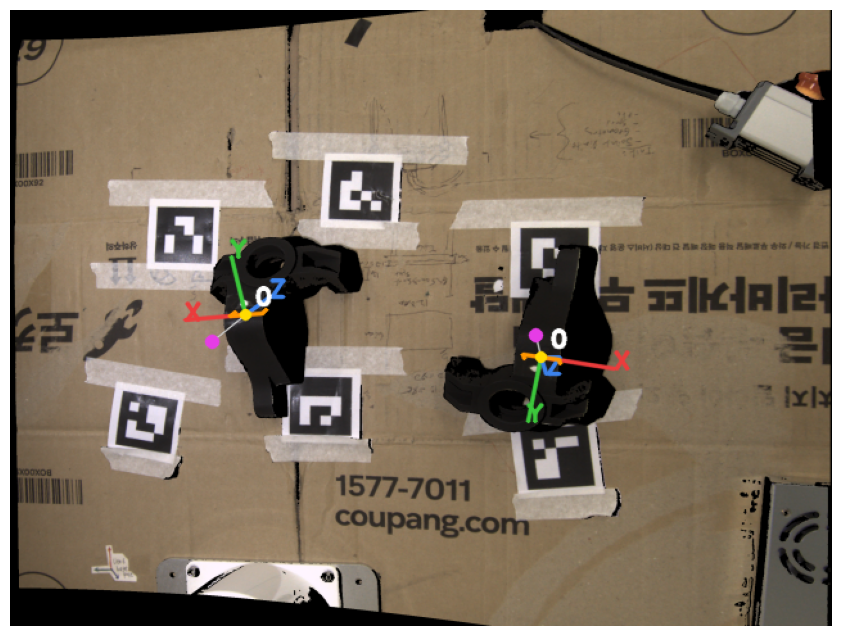

In [ ]:
def project_pts(pts_local, T, K):
    """Nx3 local-frame points -> Nx2 pixel coords, via local->camera transform T and intrinsics K."""
    pts_cam = transform_pts(pts_local, T)
    px, _ = cv2.projectPoints(pts_cam, np.zeros(3), np.zeros(3), K.astype(np.float64), np.zeros(5))
    return px[:, 0]

def draw_grasp_annotations(canvas, T, K, g, axis_len_m=0.05, idx=None):
    axis_pts = np.array([[0, 0, 0], [axis_len_m, 0, 0], [0, axis_len_m, 0], [0, 0, axis_len_m]])
    origin, x_tip, y_tip, z_tip = project_pts(axis_pts, T, K).astype(int)
    for tip, label in ((x_tip, "X"), (y_tip, "Y"), (z_tip, "Z")):
        color = AXIS_COLORS[label]
        cv2.line(canvas, tuple(origin), tuple(tip), color, 2, cv2.LINE_AA)
        cv2.putText(canvas, label, tuple(tip), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2, cv2.LINE_AA)

    # jaw fingers + opening extent, at the grasp position
    for seg_local in jaw_segments(g).values():
        p0, p1 = project_pts(seg_local, T, K).astype(int)
        cv2.line(canvas, tuple(p0), tuple(p1), JAW_COLOR, 2, cv2.LINE_AA)

    # approach axis (grasp -> hover) + hover position
    hover_pts = np.array([[0, 0, 0], [0, 0, g["hover_dist_m"]]])
    p0, p1 = project_pts(hover_pts, T, K).astype(int)
    cv2.line(canvas, tuple(p0), tuple(p1), APPROACH_COLOR, 1, cv2.LINE_AA)
    cv2.circle(canvas, tuple(p1), 5, HOVER_COLOR, -1, cv2.LINE_AA)

    # exact grasp position, drawn last so it sits on top of the axes/jaw lines
    cv2.circle(canvas, tuple(origin), 4, GRASP_COLOR, -1, cv2.LINE_AA)
    if idx is not None:
        cv2.putText(canvas, str(idx), tuple(origin + np.array([8, -8])),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2, cv2.LINE_AA)


def draw_grasps(rgb, refined, grasps, axis_len_m=0.05):
    canvas = rgb.copy()
    for r in refined:
        for idx, g in enumerate(grasps.get(r["model_id"], [])):
            T = (r["pose"] @ grasp_T(g)).astype(np.float64)
            draw_grasp_annotations(canvas, T, K, g, axis_len_m=axis_len_m, idx=idx)
    return canvas

plt.figure(figsize=(12, 8)); plt.imshow(draw_grasps(rgb, refined, GRASPS)); plt.axis("off"); plt.show()

## Grasp preview on the CAD mesh — 6 canonical views

Same grasp geometry as above (axes, jaws, approach line, hover dot), drawn directly
in the object-local frame onto `fp._meshes[model_idx]` — no camera pose involved.
Views are canonical to the mesh's own axes (its native STL orientation), not a
physically labeled "front" of the part.

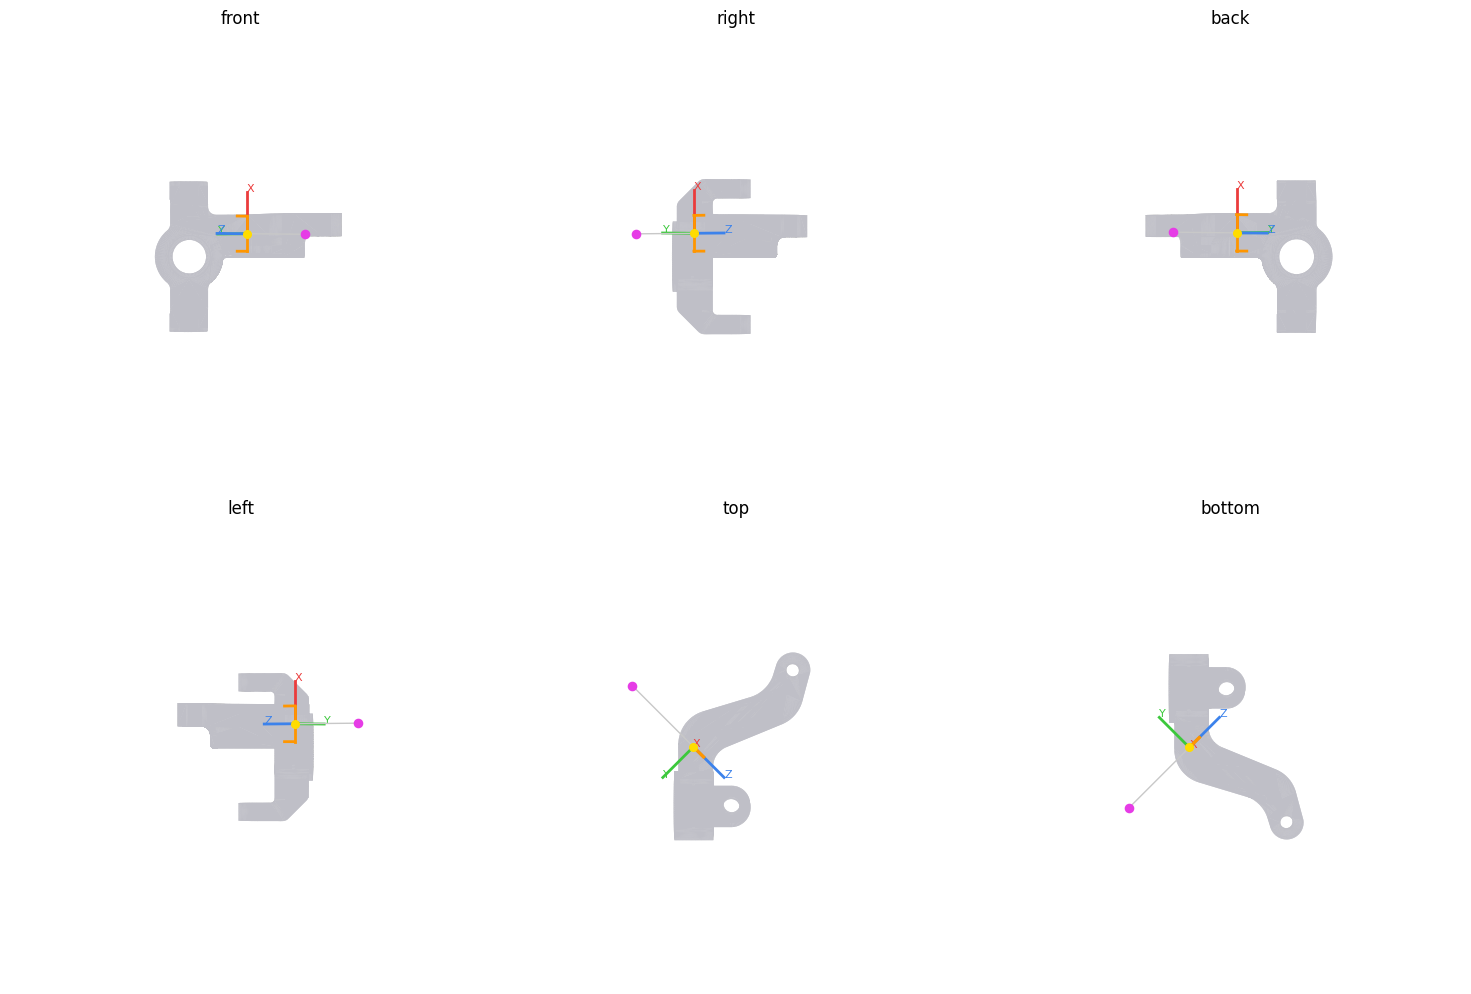

In [17]:
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

VIEW_ANGLES = {
    "front":  dict(elev=0,   azim=0),
    "right":  dict(elev=0,   azim=-90),
    "back":   dict(elev=0,   azim=180),
    "left":   dict(elev=0,   azim=90),
    "top":    dict(elev=90,  azim=-90),
    "bottom": dict(elev=-90, azim=-90),
}

def draw_grasp_3d(ax, T, g, axis_len_m=0.03, zorder=10):
    origin = T[:3, 3]
    axes_local = {"X": [axis_len_m, 0, 0], "Y": [0, axis_len_m, 0], "Z": [0, 0, axis_len_m]}
    for label, vec in axes_local.items():
        tip = transform_pts(np.array([vec]), T)[0]
        color = np.array(AXIS_COLORS[label]) / 255
        ax.plot3D(*zip(origin, tip), color=color, linewidth=2, zorder=zorder)
        ax.text(*tip, label, color=color, fontsize=8, zorder=zorder)

    for seg_local in jaw_segments(g).values():
        seg = transform_pts(seg_local, T)
        ax.plot3D(*zip(*seg), color=np.array(JAW_COLOR) / 255, linewidth=2, zorder=zorder)

    hover_local = np.array([[0, 0, 0], [0, 0, g["hover_dist_m"]]])
    hover_pts = transform_pts(hover_local, T)
    ax.plot3D(*zip(*hover_pts), color=np.array(APPROACH_COLOR) / 255, linewidth=1, zorder=zorder)
    ax.scatter(*hover_pts[1], color=np.array(HOVER_COLOR) / 255, s=35, depthshade=False, zorder=zorder + 1)

    # exact grasp position, drawn last so it sits on top
    ax.scatter(*origin, color=np.array(GRASP_COLOR) / 255, s=30, depthshade=False, zorder=zorder + 1)


def render_grasp_views(mesh, grasps_for_model, figsize=(15, 10)):
    fig = plt.figure(figsize=figsize)
    lo, hi = mesh.bounds
    center = (lo + hi) / 2
    radius = np.linalg.norm(hi - lo) / 2

    for i, (name, angles) in enumerate(VIEW_ANGLES.items()):
        ax = fig.add_subplot(2, 3, i + 1, projection="3d")
        # mplot3d depth-sorts whole artists by average depth, which regularly buries
        # thin annotation lines/points inside an opaque mesh collection. Disabling
        # automatic depth sorting and using explicit zorder instead guarantees the
        # grasp indicators always render on top of the mesh.
        ax.computed_zorder = False

        mesh_poly = Poly3DCollection(
            mesh.triangles, facecolor=(0.75, 0.75, 0.78), edgecolor="none", alpha=1.0
        )
        mesh_poly.set_zorder(1)
        ax.add_collection3d(mesh_poly)

        for g in grasps_for_model:
            draw_grasp_3d(ax, grasp_T(g), g, zorder=10)

        ax.set_xlim(center[0] - radius, center[0] + radius)
        ax.set_ylim(center[1] - radius, center[1] + radius)
        ax.set_zlim(center[2] - radius, center[2] + radius)
        ax.set_box_aspect((1, 1, 1))
        ax.view_init(elev=angles["elev"], azim=angles["azim"])
        ax.set_title(name)
        ax.set_axis_off()

    plt.tight_layout()
    plt.show()


mesh_by_id = dict(zip(MODEL_IDS, fp._meshes))
for mid, grasp_list in GRASPS.items():
    render_grasp_views(mesh_by_id[mid], grasp_list)

In [18]:
SELECTED = {"steering_knuckle": [0]}
chosen = {mid: [GRASPS[mid][i] for i in idxs] for mid, idxs in SELECTED.items()}
chosen

{'steering_knuckle': [{'t_m': [-0.01, 0.005, 0.0125],
   'approach_azimuth_deg': -45,
   'approach_elevation_deg': 0,
   'jaw_roll_deg': 90,
   'jaw_width_m': 0.025,
   'jaw_length_m': 0.01,
   'hover_dist_m': -0.06}]}

In [19]:
print(refined)

[{'pose': array([[ 0.27354673,  0.02532499,  0.96152514,  0.06861962],
       [-0.44168228, -0.8847194 ,  0.14895737,  0.0335801 ],
       [ 0.8544524 , -0.46543548, -0.23082653,  0.6604871 ],
       [ 0.        ,  0.        ,  0.        ,  1.        ]],
      dtype=float32), 'fp_score': 53.03125, 'sam6d_score': 0.5515255331993103, 'mask': array([[False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       ...,
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False]], shape=(480, 640)), 'box': array([338, 183, 470, 328]), 'detection_idx': 1, 'model_idx': 0, 'model_id': 'steering_knuckle', 'pose_base': array([[ 0.4279385 ,  0.88471105, -0.18481043,  0.24749222],
       [-0.11124697, -0.15136417, -0.98219793, -0.22186282],
       [-0.89693514,  0.44087997,  0.03364692,  0.0

In [20]:
import json, pathlib
pathlib.Path("grasps").mkdir(exist_ok=True)
json.dump(chosen, open("grasps/manual_grasps.json", "w"), indent=2)
print(f"Saved {sum(len(v) for v in chosen.values())} grasp(s) -> grasps/manual_grasps.json")

Saved 1 grasp(s) -> grasps/manual_grasps.json


In [21]:
# Resolve the chosen grasp(s) to base-frame targets for the end-effector:
#   hover = straight-line backoff position + orientation, before closing the gripper
#   grip  = the final XYZ the gripper closes at (SAME orientation as hover — the
#           approach is a straight line along the gripper's Z axis, no wrist
#           rotation between hover and grip)
end_effector_targets = []
for r in refined:
    for g in chosen.get(r["model_id"], []):
        T_grip_base  = r["pose_base"] @ grasp_T(g)
        T_hover_base = r["pose_base"] @ hover_T(g)
        end_effector_targets.append({
            "model_id": r["model_id"],
            "hover_xyz_m": T_hover_base[:3, 3].tolist(),
            "hover_rpy_deg": Rotation.from_matrix(T_hover_base[:3, :3]).as_euler("xyz", degrees=True).tolist(),
            "grip_xyz_m": T_grip_base[:3, 3].tolist(),
        })

for t in end_effector_targets:
    hx, hy, hz = t["hover_xyz_m"]
    hr, hp, hyaw = t["hover_rpy_deg"]
    gx, gy, gz = t["grip_xyz_m"]
    print(
        f"{t['model_id']:16s}"
        f"  hover_xyz_m=({hx:+.4f}, {hy:+.4f}, {hz:+.4f})"
        f"  hover_rpy_deg=({hr:+.1f}, {hp:+.1f}, {hyaw:+.1f})"
        f"  grip_xyz_m=({gx:+.4f}, {gy:+.4f}, {gz:+.4f})"
    )

end_effector_targets

steering_knuckle  hover_xyz_m=(+0.2647, -0.2355, +0.1122)  hover_rpy_deg=(+161.2, -1.9, -100.7)  grip_xyz_m=(+0.2453, -0.2338, +0.0554)
steering_knuckle  hover_xyz_m=(+0.2662, -0.0164, +0.1092)  hover_rpy_deg=(+161.5, +2.4, +92.8)  grip_xyz_m=(+0.2853, -0.0178, +0.0523)


[{'model_id': 'steering_knuckle',
  'hover_xyz_m': [0.2647054793501039,
   -0.2354866703199095,
   0.11218058372208907],
  'hover_rpy_deg': [161.17598681582302,
   -1.928189011606184,
   -100.6561849238985],
  'grip_xyz_m': [0.24532626162875212,
   -0.2337846415101118,
   0.055421895215724895]},
 {'model_id': 'steering_knuckle',
  'hover_xyz_m': [0.2662266457343938,
   -0.016369399209450776,
   0.10919997964109039],
  'hover_rpy_deg': [161.54674390936904, 2.398504151032307, 92.83022688838044],
  'grip_xyz_m': [0.2853129414269518,
   -0.017810603496364756,
   0.052334903573764524]}]